In [ ]:
# Setup
!pip install -q faiss-cpu rank-bm25 groq pandas matplotlib seaborn scikit-learn

import os, re, json, time, gc, random, glob
import numpy as np, pandas as pd
from google.colab import drive
drive.mount('/content/drive')

SEED = 42
random.seed(SEED); np.random.seed(SEED)

BASE = '/content/drive/MyDrive/rag_term_paper'
PROC = f'{BASE}/data/processed'
EMB  = f'{BASE}/data/embeddings'
RES  = f'{BASE}/results'
os.makedirs(RES, exist_ok=True)
print("Setup complete.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Setup complete.


In [ ]:
# Load Frozen Assets
chunks    = json.load(open(f'{PROC}/chunks.json'))
queries   = json.load(open(f'{PROC}/eval_queries.json'))
chunk_ids = json.load(open(f'{EMB}/chunk_ids.json'))
doc_emb   = np.load(f'{EMB}/doc_embeddings.npy').astype('float32')
q_emb     = np.load(f'{EMB}/query_embeddings.npy').astype('float32')

chunk_text_by_id = {c['chunk_id']: c['text'] for c in chunks}
qidx = {q['query_id']: i for i, q in enumerate(queries)}
num_chunks, dim = doc_emb.shape
print(f"Loaded: {num_chunks} chunks ({dim}-dim), {len(queries)} queries")

Loaded: 345 chunks (384-dim), 20 queries


In [ ]:
# Rebuild Retrieval Functions
import faiss
from rank_bm25 import BM25Okapi
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

def tok(t):
    return [w for w in re.findall(r'[a-z0-9]+', t.lower())
            if w not in ENGLISH_STOP_WORDS]

bm25 = BM25Okapi([tok(c['text']) for c in chunks])
flat = faiss.IndexFlatIP(dim)
flat.add(doc_emb)

def dense_rank(qi, k=20):
    _, ix = flat.search(q_emb[qi:qi+1], k)
    return [chunk_ids[i] for i in ix[0]]

def bm25_rank(text, k=20):
    sc = bm25.get_scores(tok(text))
    return [chunk_ids[i] for i in np.argsort(sc)[::-1][:k]]

def rrf(lists, k=60, top=20, weights=None):
    weights = weights or [1.0] * len(lists)
    score = {}
    for w, lst in zip(weights, lists):
        for r, cid in enumerate(lst, 1):
            score[cid] = score.get(cid, 0) + w / (k + r)
    return [c for c, _ in sorted(score.items(), key=lambda x: -x[1])[:top]]

def hybrid_rank(qi, top=20):
    return rrf([dense_rank(qi, 20),
                bm25_rank(queries[qi]['query'], 20)], top=top)

print("Retrieval functions ready (Dense & Hybrid).")

Retrieval functions ready (Dense & Hybrid).


In [ ]:
# Generation with Groq (40 calls, auto-model select)
from groq import Groq
import getpass

groq_client = Groq(api_key=getpass.getpass('Groq API key: ').strip())

GEN_CANDIDATES = [
    'meta-llama/llama-4-scout-17b-16e-instruct',
    'openai/gpt-oss-120b',
    'qwen/qwen3-32b',
    'openai/gpt-oss-20b',
    'llama-3.1-8b-instant',
]
available_models = {m.id for m in groq_client.models.list().data}
GEN_MODEL = next((m for m in GEN_CANDIDATES if m in available_models), None)
assert GEN_MODEL is not None, f"No suitable generator found in: {sorted(available_models)}"
print(f"Selected Generator Model: {GEN_MODEL}")

TOP_K = 5
REFUSAL = 'I cannot answer this question based on the provided context.'
SYSTEM = (f'Answer the question using ONLY the context passages. If they do '
          f'not contain enough evidence, reply exactly: "{REFUSAL}" '
          f'Do not use outside knowledge.')
GEN_CACHE = f'{RES}/generations.jsonl'

def read_jsonl(path):
    return [json.loads(l) for l in open(path)] if os.path.exists(path) else []

def call_groq(user, retries=6):
    for a in range(retries):
        try:
            r = groq_client.chat.completions.create(
                model=GEN_MODEL, temperature=0, max_tokens=1200,
                messages=[{'role': 'system', 'content': SYSTEM},
                          {'role': 'user', 'content': user}])
            ans = (r.choices[0].message.content or '').strip()
            ans = re.sub(r'<think>.*?</think>', '', ans, flags=re.DOTALL).strip()
            return ans
        except Exception as e:
            print(f'  attempt {a+1}/{retries}: {str(e)[:160]}')
            m = re.search(r'try again in ([\d.]+)s', str(e))
            time.sleep(min(float(m.group(1)) + 1.5 if m else 3 * (2 ** a), 90))
    raise RuntimeError('Groq exhausted — re-run cell later to resume.')

systems = {
    'dense':  lambda qi: dense_rank(qi, TOP_K),
    'hybrid': lambda qi: hybrid_rank(qi, TOP_K),
}
done = {r['key'] for r in read_jsonl(GEN_CACHE)}
for qi, q in enumerate(queries):
    for sname, retrieve in systems.items():
        key = f"{q['query_id']}|{sname}|{GEN_MODEL}|k{TOP_K}"
        if key in done:
            continue
        ids = retrieve(qi)
        ctx = '\n\n'.join(f'[{c}]: {chunk_text_by_id[c]}' for c in ids)
        ans = call_groq(
            f"Context passages:\n{ctx}\n\nQuestion: {q['query']}\nAnswer:")
        with open(GEN_CACHE, 'a') as f:
            f.write(json.dumps({
                'key': key, 'query_id': q['query_id'], 'system': sname,
                'model': GEN_MODEL, 'top_k': TOP_K,
                'chunk_ids': ids, 'answer': ans}) + '\n')
        time.sleep(2.2)
        print(f"  ✓ {q['query_id']}|{sname}")

print(f'\nGenerations complete: {len(read_jsonl(GEN_CACHE))}/40')

Groq API key: ··········
Selected Generator Model: openai/gpt-oss-120b
  ✓ q01|dense
  ✓ q01|hybrid
  ✓ q02|dense
  ✓ q02|hybrid
  ✓ q03|dense
  ✓ q03|hybrid
  ✓ q04|dense
  ✓ q04|hybrid
  ✓ q05|dense
  ✓ q05|hybrid
  ✓ q06|dense
  ✓ q06|hybrid
  ✓ q07|dense
  ✓ q07|hybrid
  ✓ q08|dense
  ✓ q08|hybrid
  ✓ q09|dense
  ✓ q09|hybrid
  ✓ q10|dense
  ✓ q10|hybrid
  ✓ q11|dense
  ✓ q11|hybrid
  ✓ q12|dense
  ✓ q12|hybrid
  ✓ q13|dense
  ✓ q13|hybrid
  ✓ q14|dense
  ✓ q14|hybrid
  ✓ q15|dense
  ✓ q15|hybrid
  ✓ q16|dense
  ✓ q16|hybrid
  ✓ q17|dense
  ✓ q17|hybrid
  ✓ q18|dense
  ✓ q18|hybrid
  ✓ q19|dense
  ✓ q19|hybrid
  ✓ q20|dense
  ✓ q20|hybrid

Generations complete: 40/40


In [ ]:
# Blind A/B Judge via Groq (Distinct Model Family)
JUDGE_CANDIDATES = [
    'openai/gpt-oss-120b',
    'qwen/qwen3-32b',
    'meta-llama/llama-4-scout-17b-16e-instruct',
    'openai/gpt-oss-20b',
]
available_models = {m.id for m in groq_client.models.list().data}
JUDGE_MODEL = next((m for m in JUDGE_CANDIDATES if m in available_models and m != GEN_MODEL), None)
assert JUDGE_MODEL is not None, f"No distinct judge model found: {sorted(available_models)}"
print(f"Generator: {GEN_MODEL} | Blind Judge: {JUDGE_MODEL}")

JUDGE_CACHE = f'{RES}/judgements.jsonl'
JUDGE_SYS = (
    'You grade answers produced by a RAG system. For EACH answer give: '
    'faithfulness (float 0.0 to 1.0): the share of factual claims supported by THAT '
    "answer's context passages; relevance (float 0.0 to 1.0): how directly the answer "
    'addresses the question. Reply ONLY with valid JSON (no markdown fences): '
    '{"A": {"faithfulness": 0.0, "relevance": 0.0, "note": ""}, '
    '"B": {"faithfulness": 0.0, "relevance": 0.0, "note": ""}}')

def ctx_of(rec):
    return '\n\n'.join(f'[{c}]: {chunk_text_by_id[c]}' for c in rec['chunk_ids'])

def parse_judge_json(raw):
    cleaned = re.sub(r'<think>.*?</think>', '', raw, flags=re.DOTALL).strip()
    cleaned = re.sub(r'^```(?:json)?|```$', '', cleaned, flags=re.MULTILINE).strip()
    m = re.search(r'\{.*\}', cleaned, flags=re.DOTALL)
    return json.loads(m.group(0) if m else cleaned)

def call_judge(prompt, retries=6):
    for a in range(retries):
        try:
            r = groq_client.chat.completions.create(
                model=JUDGE_MODEL,
                temperature=0,
                max_tokens=1500,
                messages=[{'role': 'system', 'content': JUDGE_SYS},
                          {'role': 'user', 'content': prompt}],
            )
            return parse_judge_json(r.choices[0].message.content or '')
        except Exception as e:
            err = str(e)
            print(f'  judge attempt {a+1}/{retries}: {err[:140]}')
            m = re.search(r'try again in ([\d.]+)s', err)
            time.sleep(min(float(m.group(1)) + 2.0 if m else 4 * (2 ** a), 90))
    raise RuntimeError('Judge exhausted — re-run cell later to resume.')

gens = {(r['query_id'], r['system']): r for r in read_jsonl(GEN_CACHE)}
judged = {r['query_id'] for r in read_jsonl(JUDGE_CACHE)}
rng = random.Random(SEED)

n_new = 0
for q in queries:
    qid = q['query_id']
    if qid in judged:
        continue
    if (qid, 'dense') not in gens or (qid, 'hybrid') not in gens:
        continue
    a_rec, b_rec = gens[(qid, 'dense')], gens[(qid, 'hybrid')]
    both_refused = REFUSAL in a_rec['answer'] and REFUSAL in b_rec['answer']
    if both_refused:
        print(f"  - Skipped {qid} (both systems refused)")
        continue
    first, second = (b_rec, a_rec) if rng.random() < 0.5 else (a_rec, b_rec)
    prompt = (f"Question: {q['query']}\n\n--- Answer A ---\n"
              f"Context:\n{ctx_of(first)}\nAnswer: {first['answer']}\n\n"
              f"--- Answer B ---\nContext:\n{ctx_of(second)}\n"
              f"Answer: {second['answer']}")
    scores = call_judge(prompt)
    mapping = {'A': first['system'], 'B': second['system']}
    with open(JUDGE_CACHE, 'a') as f:
        f.write(json.dumps({
            'query_id': qid, 'judge': JUDGE_MODEL,
            'scores': {mapping[k]: v for k, v in scores.items()}
        }) + '\n')
    n_new += 1
    print(f"  ✓ Judged {qid} ({n_new})")
    time.sleep(2.5)

print(f"\nTotal judged: {len(read_jsonl(JUDGE_CACHE))}")

Generator: openai/gpt-oss-120b | Blind Judge: openai/gpt-oss-20b
  ✓ Judged q01 (1)
  ✓ Judged q02 (2)
  ✓ Judged q03 (3)
  ✓ Judged q04 (4)
  ✓ Judged q05 (5)
  ✓ Judged q06 (6)
  ✓ Judged q07 (7)
  ✓ Judged q08 (8)
  ✓ Judged q09 (9)
  ✓ Judged q10 (10)
  ✓ Judged q11 (11)
  - Skipped q12 (both systems refused)
  ✓ Judged q13 (12)
  ✓ Judged q14 (13)
  ✓ Judged q15 (14)
  - Skipped q16 (both systems refused)
  - Skipped q17 (both systems refused)
  - Skipped q18 (both systems refused)
  - Skipped q19 (both systems refused)
  - Skipped q20 (both systems refused)

Total judged: 14


In [ ]:
# ============================================================
# CELL 5 — Aggregate: Refusal Metrics + Quality
# ============================================================
gen = pd.DataFrame(read_jsonl(GEN_CACHE))
gen['refused'] = gen['answer'].str.contains(REFUSAL, regex=False)
gen = gen.merge(pd.DataFrame(queries)[['query_id', 'category', 'answerable']],
                on='query_id')

# Deterministic refusal metrics
rows = []
for s, g in gen.groupby('system'):
    oos, inn = g[~g.answerable], g[g.answerable]
    rows.append({
        'System': s,
        'Correct_refusal_rate_OOS': round(oos.refused.mean(), 3),
        'Hallucination_rate_OOS': round(1 - oos.refused.mean(), 3),
        'False_refusal_rate_IS': round(inn.refused.mean(), 3)
    })
refusal = pd.DataFrame(rows)
refusal.to_csv(f'{RES}/layer3_refusal_metrics.csv', index=False)
print("=== REFUSAL METRICS ==="); display(refusal)

# Judged quality
J = []
for r in read_jsonl(JUDGE_CACHE):
    for s, v in r['scores'].items():
        J.append({'query_id': r['query_id'], 'system': s, **v})
J = pd.DataFrame(J).merge(
    gen[['query_id', 'system', 'refused', 'answerable']],
    on=['query_id', 'system'])
J = J[~J.refused]  # judge quality only on actual answers

quality = J.groupby(['system', 'answerable'])[
    ['faithfulness', 'relevance']].agg(['mean', 'count'])
quality.to_csv(f'{RES}/layer3_quality.csv')

quality_flat = J.groupby(['system', 'answerable'], as_index=False).agg(
    faithfulness=('faithfulness', 'mean'),
    relevance=('relevance', 'mean'),
    n=('faithfulness', 'count')
)
quality_flat.to_csv(f'{RES}/layer3_quality_flat.csv', index=False)

print("\n=== GENERATION QUALITY ==="); display(quality.round(3))


=== REFUSAL METRICS ===


,System,Correct_refusal_rate_OOS,Hallucination_rate_OOS,False_refusal_rate_IS
0,dense,1.0,0.0,0.067
1,hybrid,1.0,0.0,0.200



=== GENERATION QUALITY ===


faithfulness       relevance      
                          mean count      mean count
system answerable                                   
dense  True              0.966    14     0.979    14
hybrid True              0.898    12     0.975    12

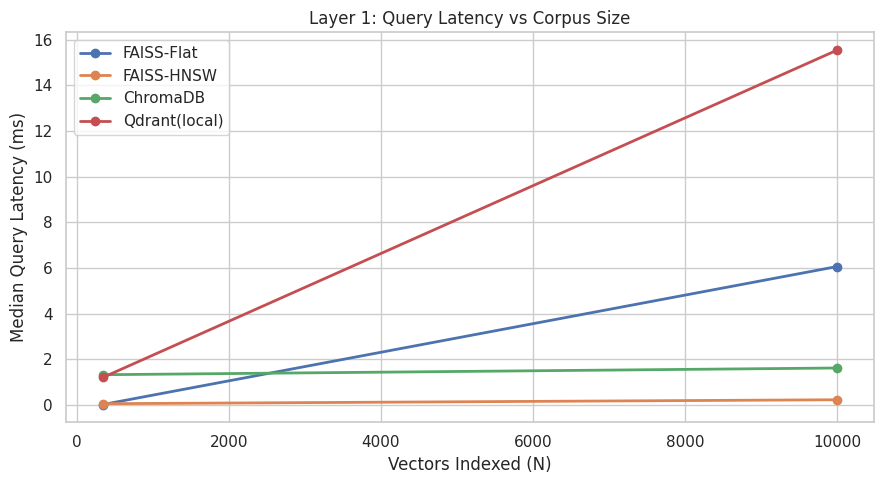

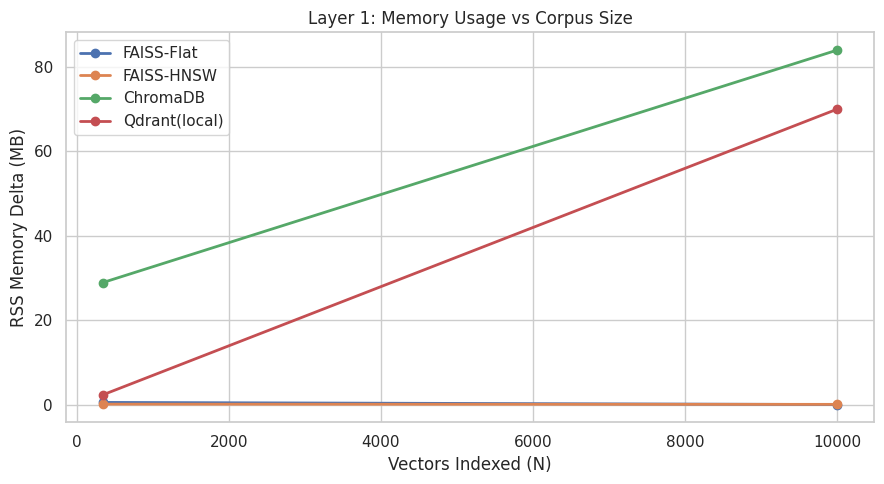

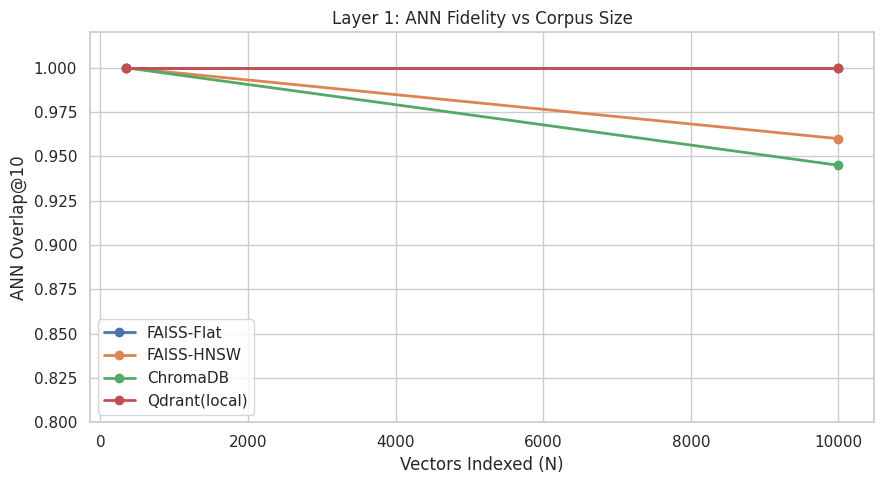

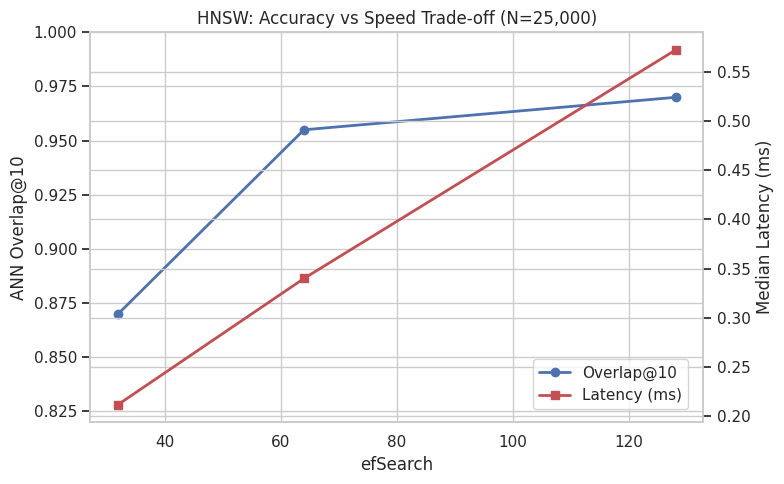

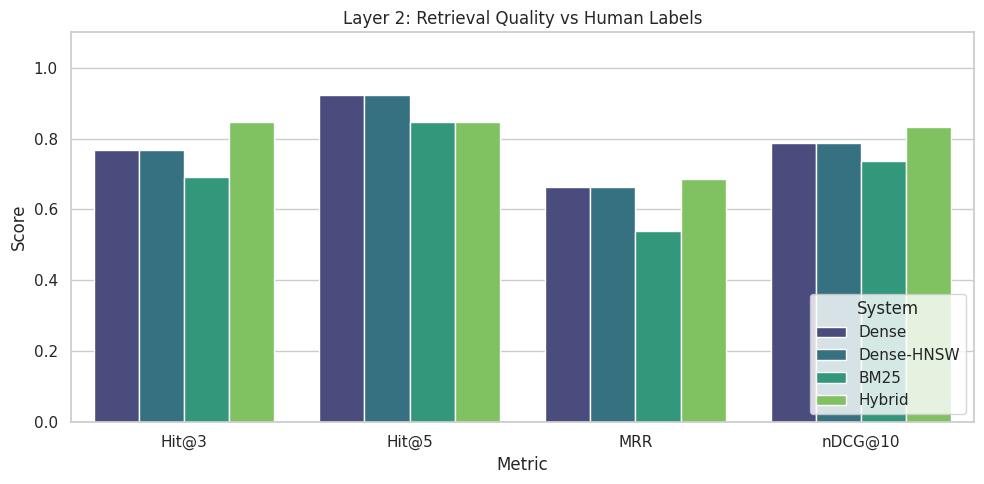

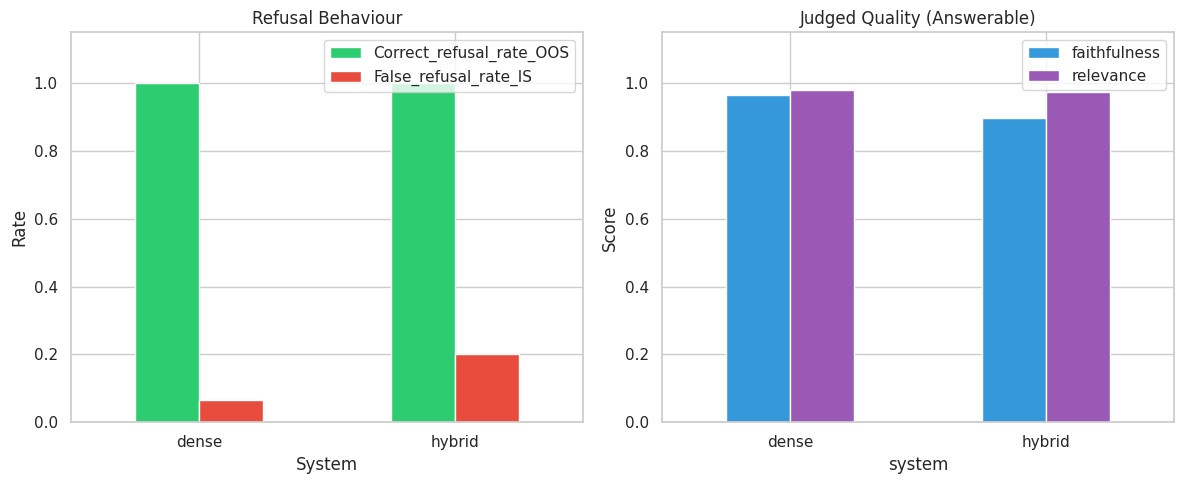

All 6 figures saved to results/


In [ ]:
# All 6 Publication Figures
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

# Fig 1: Backend Latency vs Scale
l1 = pd.read_csv(f'{RES}/layer1_scaling_raw.csv')
fig, ax = plt.subplots(figsize=(9, 5))
for backend in l1['Backend'].unique():
    sub = l1[l1.Backend == backend]
    ax.plot(sub['N'], sub['Median_ms'], 'o-', linewidth=2, label=backend)
ax.set(xlabel='Vectors Indexed (N)', ylabel='Median Query Latency (ms)',
       title='Layer 1: Query Latency vs Corpus Size')
ax.legend(); plt.tight_layout()
plt.savefig(f'{RES}/fig1_latency_vs_scale.png', dpi=300); plt.show()

# Fig 2: Memory vs Scale
fig, ax = plt.subplots(figsize=(9, 5))
for backend in l1['Backend'].unique():
    sub = l1[l1.Backend == backend]
    ax.plot(sub['N'], sub['RSS_delta_MB'], 'o-', linewidth=2, label=backend)
ax.set(xlabel='Vectors Indexed (N)', ylabel='RSS Memory Delta (MB)',
       title='Layer 1: Memory Usage vs Corpus Size')
ax.legend(); plt.tight_layout()
plt.savefig(f'{RES}/fig2_memory_vs_scale.png', dpi=300); plt.show()

# Fig 3: ANN Overlap
fig, ax = plt.subplots(figsize=(9, 5))
for backend in l1['Backend'].unique():
    sub = l1[l1.Backend == backend]
    ax.plot(sub['N'], sub['ANN_overlap@10'], 'o-', linewidth=2, label=backend)
ax.set(xlabel='Vectors Indexed (N)', ylabel='ANN Overlap@10',
       title='Layer 1: ANN Fidelity vs Corpus Size', ylim=(0.8, 1.02))
ax.legend(); plt.tight_layout()
plt.savefig(f'{RES}/fig3_ann_overlap.png', dpi=300); plt.show()

# Fig 4: HNSW efSearch Sweep
ef = pd.read_csv(f'{RES}/layer1_hnsw_ef_sweep.csv')
fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(ef['efSearch'], ef['ANN_overlap@10'], 'bo-', linewidth=2, label='Overlap@10')
ax1.set(xlabel='efSearch', ylabel='ANN Overlap@10', ylim=(0.82, 1.0))
ax2 = ax1.twinx()
ax2.plot(ef['efSearch'], ef['Median_ms'], 'rs-', linewidth=2, label='Latency (ms)')
ax2.set(ylabel='Median Latency (ms)')
ax1.set_title('HNSW: Accuracy vs Speed Trade-off (N=25,000)')
fig.legend(loc='lower right', bbox_to_anchor=(0.88, 0.15))
plt.tight_layout()
plt.savefig(f'{RES}/fig4_hnsw_ef_sweep.png', dpi=300); plt.show()

# Fig 5: Retrieval Quality (Dense vs BM25 vs Hybrid)
ret = pd.read_csv(f'{RES}/layer2_retrieval_vs_human_qrels.csv', index_col=0)
metrics = ['Hit@3', 'Hit@5', 'MRR', 'nDCG@10']
avail = [m for m in metrics if m in ret.columns]
melted = ret[avail].reset_index().melt(
    id_vars=ret.index.name or 'index',
    var_name='Metric', value_name='Score')
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=melted, x='Metric', y='Score',
            hue=ret.index.name or 'index', palette='viridis', ax=ax)
ax.set(title='Layer 2: Retrieval Quality vs Human Labels', ylim=(0, 1.1))
ax.legend(title='System', loc='lower right')
plt.tight_layout()
plt.savefig(f'{RES}/fig5_retrieval_quality.png', dpi=300); plt.show()

#Fig 6: Generation Quality & Refusal Behaviour
ref = pd.read_csv(f'{RES}/layer3_refusal_metrics.csv')
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ref.set_index('System')[['Correct_refusal_rate_OOS', 'False_refusal_rate_IS']].plot(
    kind='bar', ax=axes[0], rot=0, color=['#2ecc71', '#e74c3c'])
axes[0].set(title='Refusal Behaviour', ylabel='Rate', ylim=(0, 1.15))

qual = pd.read_csv(f'{RES}/layer3_quality_flat.csv')
qual_plot = qual.groupby('system')[['faithfulness', 'relevance']].mean()
qual_plot.plot(kind='bar', ax=axes[1], rot=0, color=['#3498db', '#9b59b6'])
axes[1].set(title='Judged Quality (Answerable)', ylabel='Score', ylim=(0, 1.15))

plt.tight_layout()
plt.savefig(f'{RES}/fig6_generation_quality.png', dpi=300); plt.show()
print("All 6 figures saved to results/")

In [ ]:
# Decision Matrix
big = l1[l1.N == l1.N.max()].set_index('Backend')
ret = pd.read_csv(f'{RES}/layer2_retrieval_vs_human_qrels.csv', index_col=0)
qual_df = pd.read_csv(f'{RES}/layer3_quality_flat.csv').set_index('system')

fast = big['Median_ms'].idxmin()
lean = big['RSS_delta_MB'].idxmin()
best_ret = ret['nDCG@10'].idxmax()
best_faith = qual_df['faithfulness'].idxmax()

matrix = pd.DataFrame([
    {'Criterion': f'Lowest query latency (N={int(l1.N.max())})',
     'Winner': fast,
     'Evidence': f"{big.loc[fast, 'Median_ms']:.3f} ms median (ANN_overlap@10={big.loc[fast, 'ANN_overlap@10']:.3f})"},
    {'Criterion': f'Lowest memory growth (N={int(l1.N.max())})',
     'Winner': lean,
     'Evidence': f"{big.loc[lean, 'RSS_delta_MB']:.2f} MB RSS delta"},
    {'Criterion': 'Best retrieval ranking quality (human qrels)',
     'Winner': best_ret,
     'Evidence': f"nDCG@10={ret.loc[best_ret, 'nDCG@10']:.3f}, MRR={ret.loc[best_ret, 'MRR']:.3f}, Recall@10={ret.loc[best_ret, 'Recall@10']:.3f}"},
    {'Criterion': 'Highest downstream generation faithfulness',
     'Winner': best_faith,
     'Evidence': f"Faithfulness={qual_df.loc[best_faith, 'faithfulness']:.3f}, False refusal={ref.set_index('System').loc[best_faith, 'False_refusal_rate_IS']:.3f}"},
])
matrix.to_csv(f'{RES}/decision_matrix.csv', index=False)
print("=== DECISION MATRIX ==="); display(matrix)

=== DECISION MATRIX ===


,Criterion,Winner,Evidence
0,Lowest query latency (N=10000),FAISS-HNSW,0.231 ms median (ANN_overlap@10=0.960)
1,Lowest memory growth (N=10000),FAISS-Flat,0.00 MB RSS delta
2,Best retrieval ranking quality (human qrels),Hybrid,"nDCG@10=0.832, MRR=0.686, Recall@10=0.974"
3,Highest downstream generation faithfulness,dense,"Faithfulness=0.966, False refusal=0.067"


In [ ]:
# Modularize Project Structure
import subprocess

for folder in (f'{BASE}/src', f'{BASE}/scripts', f'{BASE}/notebooks'):
    os.makedirs(folder, exist_ok=True)

# src/retrieval.py
with open(f'{BASE}/src/retrieval.py', 'w') as f:
    f.write('''import re
import numpy as np
import faiss
from rank_bm25 import BM25Okapi
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

def tokenize(text: str):
    return [w for w in re.findall(r"[a-z0-9]+", text.lower())
            if w not in ENGLISH_STOP_WORDS]

class HybridRetriever:
    def __init__(self, chunks, doc_emb: np.ndarray, ef_search: int = 64):
        self.chunks = chunks
        self.chunk_ids = [c["chunk_id"] for c in chunks]
        self.doc_emb = doc_emb.astype("float32")
        dim = self.doc_emb.shape[1]

        self.bm25 = BM25Okapi([tokenize(c["text"]) for c in chunks])

        self.flat = faiss.IndexFlatIP(dim)
        self.flat.add(self.doc_emb)

        self.hnsw = faiss.IndexHNSWFlat(dim, 32, faiss.METRIC_INNER_PRODUCT)
        self.hnsw.hnsw.efConstruction = 200
        self.hnsw.hnsw.efSearch = ef_search
        self.hnsw.add(self.doc_emb)

    def dense_search(self, q_vec: np.ndarray, k: int = 20, use_hnsw: bool = False):
        index = self.hnsw if use_hnsw else self.flat
        _, ix = index.search(q_vec.reshape(1, -1).astype("float32"), k)
        return [self.chunk_ids[i] for i in ix[0]]

    def bm25_search(self, query_text: str, k: int = 20):
        scores = self.bm25.get_scores(tokenize(query_text))
        return [self.chunk_ids[i] for i in np.argsort(scores)[::-1][:k]]

    @staticmethod
    def reciprocal_rank_fusion(ranked_lists, k: int = 60, top: int = 20, weights=None):
        weights = weights or [1.0] * len(ranked_lists)
        scores = {}
        for w, lst in zip(weights, ranked_lists):
            for rank, cid in enumerate(lst, 1):
                scores[cid] = scores.get(cid, 0.0) + w / (k + rank)
        return [cid for cid, _ in sorted(scores.items(), key=lambda x: -x[1])[:top]]

    def hybrid_search(self, query_text: str, q_vec: np.ndarray, top: int = 20):
        return self.reciprocal_rank_fusion(
            [self.dense_search(q_vec, k=20), self.bm25_search(query_text, k=20)],
            top=top,
        )
''')

# src/metrics.py
with open(f'{BASE}/src/metrics.py', 'w') as f:
    f.write('''import numpy as np
import pandas as pd

def dcg(gains):
    return sum(g / np.log2(i + 2) for i, g in enumerate(gains))

def evaluate_retrieval(run: dict, qrels: dict, qids: list, ks=(1, 3, 5, 10)) -> pd.DataFrame:
    rows = []
    for qid in qids:
        rel = qrels[qid]
        good = {c for c, g in rel.items() if g == 2}
        if not good:
            continue
        ranked = run[qid]
        row = {"query_id": qid}
        for k in ks:
            top = set(ranked[:k])
            row[f"Hit@{k}"] = float(bool(good & top))
            row[f"Recall@{k}"] = len(good & top) / len(good)
        row["MRR"] = next((1 / (i + 1) for i, c in enumerate(ranked) if c in good), 0.0)
        gains = [rel.get(c, 0) for c in ranked[:10]]
        ideal = sorted(rel.values(), reverse=True)[:10]
        row["nDCG@10"] = dcg(gains) / dcg(ideal) if dcg(ideal) else 0.0
        rows.append(row)
    return pd.DataFrame(rows)
''')

# scripts/download_corpus.py
with open(f'{BASE}/scripts/download_corpus.py', 'w') as f:
    f.write('''import os, time, urllib.request
import pandas as pd

PAPERS = {
    "doc01_rag_original":      "https://arxiv.org/pdf/2005.11401.pdf",
    "doc02_rag_survey":        "https://arxiv.org/pdf/2312.10997.pdf",
    "doc03_dpr":               "https://arxiv.org/pdf/2004.04906.pdf",
    "doc04_ragas":             "https://arxiv.org/pdf/2309.15217.pdf",
    "doc05_self_rag":          "https://arxiv.org/pdf/2310.11511.pdf",
    "doc06_transformer":       "https://arxiv.org/pdf/1706.03762.pdf",
    "doc07_lora":              "https://arxiv.org/pdf/2106.09685.pdf",
    "doc08_flash_attention":   "https://arxiv.org/pdf/2205.14135.pdf",
    "doc09_rag_survey_huang":  "https://arxiv.org/pdf/2404.10981.pdf",
    "doc10_comprehensive_rag": "https://arxiv.org/pdf/2410.12837.pdf",
}

def download_all(pdf_dir="data/raw_pdfs", proc_dir="data/processed"):
    os.makedirs(pdf_dir, exist_ok=True)
    os.makedirs(proc_dir, exist_ok=True)
    opener = urllib.request.build_opener()
    opener.addheaders = [("User-Agent", "Mozilla/5.0 (Research Benchmark Script)")]
    urllib.request.install_opener(opener)

    for doc_id, url in PAPERS.items():
        dest = os.path.join(pdf_dir, f"{doc_id}.pdf")
        if not os.path.exists(dest):
            print(f"Downloading {doc_id}...")
            urllib.request.urlretrieve(url, dest)
            time.sleep(1)

    manifest = pd.DataFrame([
        {"doc_id": k, "url": v, "filename": f"{k}.pdf"} for k, v in PAPERS.items()
    ])
    manifest.to_csv(os.path.join(proc_dir, "corpus_manifest.csv"), index=False)

if __name__ == "__main__":
    download_all()
''')

# requirements.txt
pkgs = subprocess.check_output(
    "pip freeze | grep -iE 'faiss|chroma|qdrant|rank-bm25|sentence-transformers|numpy|pandas|psutil|pymupdf|tiktoken|groq|google-genai|matplotlib|seaborn|scikit-learn'",
    shell=True, text=True
)
with open(f'{BASE}/requirements.txt', 'w') as f:
    f.write(pkgs)

# README.md populated with actual benchmark CSV tables
l1_md = pd.read_csv(f'{RES}/layer1_scaling_raw.csv').to_markdown(index=False)
l2_md = pd.read_csv(f'{RES}/layer2_retrieval_vs_human_qrels.csv').to_markdown(index=False)
dm_md = pd.read_csv(f'{RES}/decision_matrix.csv').to_markdown(index=False)

readme_text = f"""# Comparative Evaluation of Vector Databases and Hybrid Retrieval in RAG Systems

**Author:** Dev Kumar (Roll No. 90516449725) | **Mentor:** Ms. Nidhi Sharma
**Institution:** Guru Gobind Singh Indraprastha University (NUES Term Paper III)

## Overview
A controlled, reproducible benchmark isolating vector storage backends (`FAISS-Flat`, `FAISS-HNSW`, `ChromaDB`, `Qdrant`) and retrieval strategies (`Dense`, `Dense-HNSW`, `BM25`, `Hybrid RRF`) using frozen `BAAI/bge-small-en-v1.5` embeddings across 10 AI/ML research papers (345 chunks) and 20 curated queries.

## Key Empirical Results

### Layer 1: Vector Backend Systems Benchmark
{l1_md}

### Layer 2: Information Retrieval Quality (Human-Verified Qrels)
{l2_md}

### Architectural Decision Matrix
{dm_md}

## Repository Structure
- `notebooks/` — End-to-end Colab notebooks (`01_data_pipeline.ipynb`, `02_benchmark_and_evaluate.ipynb`, `03_generation_judge_figures.ipynb`)
- `src/` — Modular retrieval (`retrieval.py`) and IR evaluation (`metrics.py`) implementations
- `scripts/` — Reproducible corpus download script (`download_corpus.py`)
- `data/processed/` — Corpus manifest, chunks, evaluation queries, and human-verified `qrels_labeled.csv`
- `results/` — Raw CSV benchmark outputs and 300-DPI figures (`fig1`–`fig6`)
"""
with open(f'{BASE}/README.md', 'w') as f:
    f.write(readme_text)

print("=== VERIFYING GENERATED ARTIFACTS ===")
for sub in ['data/processed', 'data/embeddings', 'results', 'src', 'scripts']:
    files = sorted(os.listdir(f'{BASE}/{sub}'))
    print(f"\n[{sub}/] ({len(files)} files):")
    for fn in files:
        print(f"  - {fn}")
print("\nRoot files:", [f for f in os.listdir(BASE) if os.path.isfile(f'{BASE}/{f}')])

=== VERIFYING GENERATED ARTIFACTS ===

[data/processed/] (7 files):
  - chunks.json
  - corpus_manifest.csv
  - eval_queries.json
  - numpy_exact_topk.json
  - qrels_labeled.csv
  - qrels_prelabeled.csv
  - qrels_to_label.csv

[data/embeddings/] (3 files):
  - chunk_ids.json
  - doc_embeddings.npy
  - query_embeddings.npy

[results/] (15 files):
  - decision_matrix.csv
  - fig1_latency_vs_scale.png
  - fig2_memory_vs_scale.png
  - fig3_ann_overlap.png
  - fig4_hnsw_ef_sweep.png
  - fig5_retrieval_quality.png
  - fig6_generation_quality.png
  - generations.jsonl
  - judgements.jsonl
  - layer1_hnsw_ef_sweep.csv
  - layer1_scaling_raw.csv
  - layer2_retrieval_vs_human_qrels.csv
  - layer3_quality.csv
  - layer3_quality_flat.csv
  - layer3_refusal_metrics.csv

[src/] (2 files):
  - metrics.py
  - retrieval.py

[scripts/] (1 files):
  - download_corpus.py

Root files: ['requirements.txt', 'README.md']
